**Зависимости:** `numpy`, `scipy`, `sympy`, `matplotlib`. Если они не установлены, выполните в Jupyter: `%pip install numpy scipy sympy matplotlib`. Затем запустите ячейки сверху вниз.

# Математика для программирования

## Конспект

### 1. Системы линейных алгебраических уравнений

Система линейных уравнений может быть представлена в матричном виде:

$$
Ax=b
$$

где $A$ — матрица коэффициентов, $x$ — вектор неизвестных, $b$ — вектор свободных членов.

Расширенная матрица системы записывается как:

$$
(A|b)
$$

Для приведения матрицы к приведённому ступенчатому виду используется **RREF (Reduced Row Echelon Form)**.

В Python для работы с такими задачами удобно использовать библиотеку `SymPy`:

```python
from sympy import *
init_printing()
```

После этого метод `.rref()` позволяет получить приведённую ступенчатую форму матрицы.

---

### 2. Матрицы

Основные операции над матрицами:

* сложение и вычитание;
* умножение;
* транспонирование;
* нахождение определителя;
* нахождение обратной матрицы;
* нахождение ранга;
* нахождение собственных значений и собственных векторов.

Для матриц используются `numpy` и `SymPy`.

Пример:

```python
A = Matrix([[1, 2], [3, 4]])
A.T
A.det()
A.inv()
```

---

### 3. Определитель

Определитель квадратной матрицы обозначается как $\det A$.

Если $\det A \neq 0$, то матрица является невырожденной и имеет обратную матрицу:

$$
A^{-1}
$$

Если $\det A = 0$, обратной матрицы не существует.

Для нахождения определителя в Python используется:

```python
A.det()
```

---

### 4. След матрицы

След матрицы — сумма элементов главной диагонали:

$$
tr(A)=a_{11}+a_{22}+\dots+a_{nn}
$$

В `numpy`:

```python
np.trace(A)
```

---

### 5. Обратная матрица

Обратная матрица $A^{-1}$ определяется условием:

$$
AA^{-1}=A^{-1}A=I
$$

где $I$ — единичная матрица.

Обратную матрицу можно найти с помощью:

```python
A.inv()
```

или:

```python
np.linalg.inv(A)
```

---

### 6. Собственные значения и собственные векторы

Собственное значение $\lambda$ и собственный вектор $x$ удовлетворяют:

$$
Ax=\lambda x
$$

или:

$$
(A-\lambda I)x=0
$$

В `SymPy`:

```python
A.eigenvals()
A.eigenvects()
```

В `NumPy`:

```python
np.linalg.eig(A)
```

---

### 7. Матрица Адамара

Матрица Адамара состоит из элементов $1$ и $-1$ и удовлетворяет условию:

$$
H_nH_n^T=nI_n
$$

Для матриц Адамара порядков $2^k$ используется рекуррентное построение через произведение Кронекера.

Произведение Кронекера:

```python
np.kron(A, B)
```

---

### 8. Квадратичная форма

Квадратичная форма имеет вид:

$$
Q(x)=x^TAx
$$

где $A$ — симметричная матрица.

Например:

$$
Q(x_1,x_2)=
3x_1^2+4x_1x_2+2x_2^2
$$

соответствует матрице:

$$
A=
\begin{pmatrix}
3&2\\
2&2
\end{pmatrix}
$$

Коэффициент при смешанном произведении делится между симметричными элементами матрицы.

---

### 9. Положительно и отрицательно определённые формы

Квадратичная форма является положительно определённой, если:

$$
Q(x)>0
$$

для любого ненулевого $x$.

Для симметричной матрицы можно использовать критерий Сильвестра:

$$
\Delta_1>0,\quad
\Delta_2>0,\quad
\dots,\quad
\Delta_n>0
$$

Для отрицательно определённой формы знаки главных угловых миноров чередуются:

$$
\Delta_1<0,\quad
\Delta_2>0,\quad
\Delta_3<0,\dots
$$

---

### 10. Приведение квадратичной формы к главным осям

Если матрица квадратичной формы симметрична, её можно ортогонально диагонализировать:

$$
P^TAP=D
$$

где $P$ — ортогональная матрица, а $D$ — диагональная матрица из собственных значений.

После замены координат квадратичная форма принимает канонический вид.

---

### 11. Графическое представление матриц

Для визуализации матриц используется `matplotlib`.

Например:

```python
plt.imshow(A)
plt.show()
```

Так можно изображать матрицы биномиальных коэффициентов по модулю 2 и матрицы Адамара.

---

## Используемые библиотеки

```python
import numpy as np
import scipy.linalg as la
import sympy as sp
import matplotlib.pyplot as plt
```

Для красивого отображения математических выражений:

```python
from sympy import *
init_printing()
```


In [8]:
# 1.1. RREF и общее решение
import numpy as np
from sympy import Matrix, symbols, linsolve, init_printing
from IPython.display import display

init_printing()
A = Matrix([[1, 5, -2, 0], [-3, 1, 9, -5], [4, -8, -1, 7]])
b = Matrix([-7, 9, 0])

rref_matrix, pivots = A.row_join(b).rref()
print("Приведённая ступенчатая матрица:")
display(rref_matrix)

x1, x2, x3, x4 = symbols('x1 x2 x3 x4')
print("Общее решение:")
display(linsolve((A, b), (x1, x2, x3, x4)))

Приведённая ступенчатая матрица:


⎡1  0  0  8/7   -11/7⎤
⎢                    ⎥
⎢0  1  0  -2/7  -6/7 ⎥
⎢                    ⎥
⎣0  0  1  -1/7   4/7 ⎦

Общее решение:


In [7]:
# 1.2. RREF и общее решение
from sympy import Matrix, symbols, linsolve
from IPython.display import display

A = Matrix([[5, -1, 5, 9, -2], [3, 0, 6, 9, -1], [2, 0, 4, 6, -1]])
b = Matrix([-3, 4, 0])

rref_matrix, pivots = A.row_join(b).rref()
print("Приведённая ступенчатая матрица:")
display(rref_matrix)

x1, x2, x3, x4, x5 = symbols('x1 x2 x3 x4 x5')
print("Общее решение:")
display(linsolve((A, b), (x1, x2, x3, x4, x5)))

Приведённая ступенчатая матрица:


Matrix([
[1, 0, 2, 3, 0, 4],
[0, 1, 5, 6, 0, 7],
[0, 0, 0, 0, 1, 8]])

Общее решение:


{(-2*x3 - 3*x4 + 4, -5*x3 - 6*x4 + 7, x3, x4, 8)}

In [9]:
#1.3
from sympy import Matrix, symbols, Eq, solve, simplify, expand, linsolve

x, y, z, u = symbols('x y z u')

A = Matrix([
    [32, 97, 90, 48],
    [35, 84, 91, 54],
    [17, 18, 21, 13]
])

b = Matrix([47, 40, 37])

solution = next(iter(linsolve((A, b), (x, y, z, u))))

u_from_x = solve(Eq(solution[0], x), u)[0]

y_function = expand(solution[1].subs(u, u_from_x))

a = y_function.subs(x, 0)
b_coef = y_function.coeff(x)

print("y(x) =", y_function)
print("a =", a)
print("b =", b_coef)

y(x) = 14027 - 4262*x
a = 14027
b = -4262


In [4]:
#1.4
from sympy import Matrix, init_printing

init_printing()

A = Matrix([
    [3, 0, 2],
    [0, 1, 3],
    [2, 2, 0],
    [0, 1, 0]
])

B = Matrix([
    [1, 2, -1, 2],
    [-2, -1, 1, 2],
    [2, 1, 1, 2]
])

C = Matrix([
    [0, -4, 6, 1],
    [2, 2, -5, -2],
    [2, -2, 6, 4],
    [1, 3, 0, 1]
])

result = A * B + C

result

⎡7   4  5   11⎤
⎢             ⎥
⎢6   4  -1  6 ⎥
⎢             ⎥
⎢0   0  6   12⎥
⎢             ⎥
⎣-1  2  1   3 ⎦

In [5]:
#1.5
from sympy import Matrix

for n in range(1, 7):
    A = Matrix([
        [min(i, j) for j in range(1, n + 1)]
        for i in range(1, n + 1)
    ])

    B = Matrix([
        [max(i, j) for j in range(1, n + 1)]
        for i in range(1, n + 1)
    ])

    C = Matrix([
        [abs(i - j) for j in range(1, n + 1)]
        for i in range(1, n + 1)
    ])

    print(
        f"n = {n}: "
        f"det(A) = {A.det()}, "
        f"det(B) = {B.det()}, "
        f"det(C) = {C.det()}"
    )

print()
print("Формулы:")
print("a) det(A) = 1")
print("б) det(B) = (-1)^(n-1) * n")
print("в) det(C) = (-1)^(n-1) * 2^(n-2) * (n-1), n >= 2")

n = 1: det(A) = 1, det(B) = 1, det(C) = 0
n = 2: det(A) = 1, det(B) = -2, det(C) = -1
n = 3: det(A) = 1, det(B) = 3, det(C) = 4
n = 4: det(A) = 1, det(B) = -4, det(C) = -12
n = 5: det(A) = 1, det(B) = 5, det(C) = 32
n = 6: det(A) = 1, det(B) = -6, det(C) = -80

Формулы:
a) det(A) = 1
б) det(B) = (-1)^(n-1) * n
в) det(C) = (-1)^(n-1) * 2^(n-2) * (n-1), n >= 2


In [10]:
# 1.6. Точный перебор 6 × 6 матриц из -1 и 1
from itertools import combinations, product
import numpy as np
from sympy import Matrix

# Определитель линеен по каждому элементу. Поэтому максимум по {-1,0,1}
# достигается также при элементах только из {-1,1}.
# Сменой знаков строк и столбцов первую строку и столбец делаем равными 1.
# Остаётся выбрать пять различных строк из 32 возможных (повтор дал бы det=0).
rows = [(1,) + tail for tail in product((-1, 1), repeat=5)]
maximum = 0
example = None

for chosen in combinations(range(32), 5):
    candidate = np.array([(1,) * 6] + [rows[i] for i in chosen], dtype=int)
    value = round(np.linalg.det(candidate))
    if abs(value) > maximum:
        maximum = abs(value)
        example = candidate.copy()

if round(np.linalg.det(example)) < 0:
    example[-1] *= -1

print("Матрица с максимальным определителем:")
print(example)
print("Точная проверка det =", Matrix(example.tolist()).det())
print("Максимум =", maximum)

Матрица с максимальным определителем:
[[ 1  1  1  1  1  1]
 [ 1 -1 -1 -1 -1  1]
 [ 1 -1 -1 -1  1 -1]
 [ 1 -1  1  1 -1 -1]
 [ 1  1 -1  1 -1 -1]
 [ 1  1  1 -1 -1 -1]]
Точная проверка det = 160
Максимум = 160


In [11]:
#1.7
import numpy as np

n = 80000

d = np.linspace(0.99, 1.01, n)

a12 = 0.57
a21 = 0.03

det_A = (d[0] * d[1] - a12 * a21) * np.prod(d[2:])

trace_inv_A = (
    (d[0] + d[1]) / (d[0] * d[1] - a12 * a21)
    + np.sum(1 / d[2:])
)

print("Определитель A =", det_A)
print("След обратной матрицы =", trace_inv_A)

Определитель A = 0.25897911386522593
След обратной матрицы = 80002.702766086


In [8]:
#1.8
import numpy as np

n = 43000

diagonal = np.geomspace(1, 1.07, n)
first_row = np.linspace(1, 1.10, n)

inverse_diagonal = 1 / diagonal

inverse_first_row = -first_row[1:] / diagonal[1:]

min_element = min(
    inverse_diagonal.min(),
    inverse_first_row.min()
)

sum_elements = (
    inverse_diagonal.sum()
    + inverse_first_row.sum()
)

print("Наименьший элемент B =", min_element)
print("Сумма элементов B =", sum_elements)

Наименьший элемент B = -1.0280373831775702
Сумма элементов B = -2054.438267008649


In [9]:
#1.9
import numpy as np

gamma = 0.057

A = np.array([
    [7 * gamma, 14 * gamma],
    [9 * gamma, 1 * gamma]
])

I = np.eye(2)

S = sum(
    (np.linalg.matrix_power(A, i) for i in range(4, 71)),
    np.zeros((2, 2))
)

B = np.linalg.inv(I - A) @ np.linalg.matrix_power(A, 4)

print("Матрица S_4,70:")
print(S)

print()
print("Наибольший элемент S_4,70 =", np.max(S))

print()
print("Матрица B_4:")
print(B)

print()
print("Наибольший элемент B_4 =", np.max(B))

k = None

for candidate in range(1, 150):
    limit_matrix = (
        np.linalg.inv(I - A)
        @ np.linalg.matrix_power(A, candidate)
    )

    partial = np.zeros((2, 2))
    ok = True

    for n in range(candidate, 300):
        partial += np.linalg.matrix_power(A, n)

        if n > candidate and np.max(partial) >= 0.0002:
            ok = False
            break

    if ok and np.max(limit_matrix) < 0.0002:
        k = candidate
        break

print()
print("Минимальное k =", k)

Матрица S_4,70:
[[3.60967903 3.43309957]
 [2.20699258 2.13835065]]

Наибольший элемент S_4,70 = 3.609679030803459

Матрица B_4:
[[3.61117468 3.43453189]
 [2.20791336 2.13923244]]

Наибольший элемент B_4 = 3.611174678109661

Минимальное k = 89


In [10]:
#1.10
from sympy import Matrix, symbols, expand

x = symbols('x')

M = Matrix([
    [7, 5, 5, x],
    [2, 2, 6, 9],
    [3, x, 8, 0],
    [3, 1, 1, 0]
])

det_M = expand(M.det())

print("Определитель:")
print(det_M)

print()
print("Коэффициент a =", det_M.coeff(x, 2))
print("Коэффициент b =", det_M.coeff(x, 1))

Определитель:
16*x**2 - 116*x + 576

Коэффициент a = 16
Коэффициент b = -116


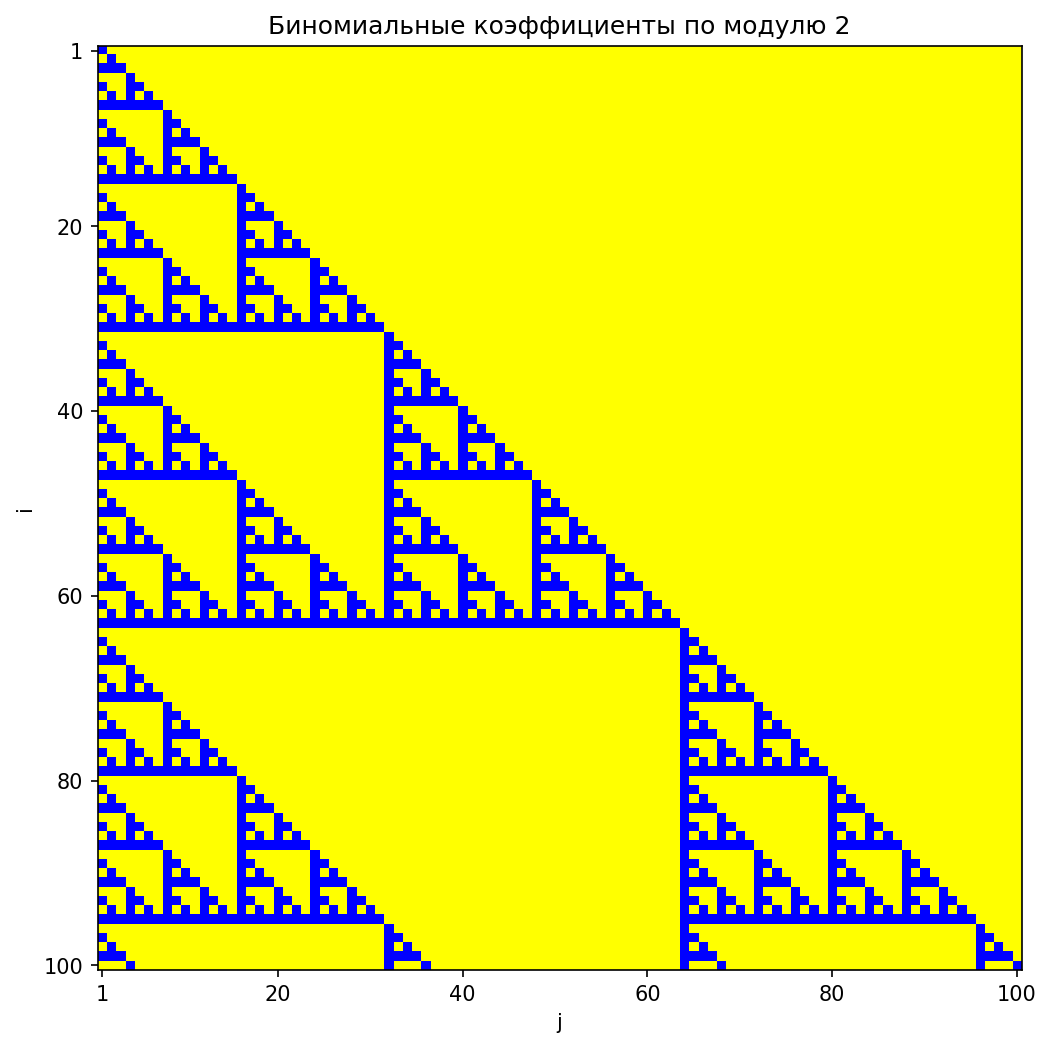

In [11]:
# 1.11. В листке индексы начинаются с 1: A[i,j] = C(i,j) mod 2.
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

n = 100
A = np.zeros((n, n), dtype=int)
for i in range(1, n + 1):
    for j in range(1, i + 1):
        A[i - 1, j - 1] = math.comb(i, j) % 2

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(A, cmap=ListedColormap(["yellow", "blue"]),
          interpolation="nearest", extent=(0.5, n + 0.5, n + 0.5, 0.5))
ax.set_title("Биномиальные коэффициенты по модулю 2")
ax.set_xlabel("j")
ax.set_ylabel("i")
ax.set_xticks([1, 20, 40, 60, 80, 100])
ax.set_yticks([1, 20, 40, 60, 80, 100])
plt.show()

H1:
[[1]]

H2:
[[ 1  1]
 [ 1 -1]]

H4:
[[ 1  1  1  1]
 [ 1 -1  1 -1]
 [ 1  1 -1 -1]
 [ 1 -1 -1  1]]

Проверка H4 = H2 ⊗ H2:
True

Проверка H64 = H2 ⊗ H32:
True


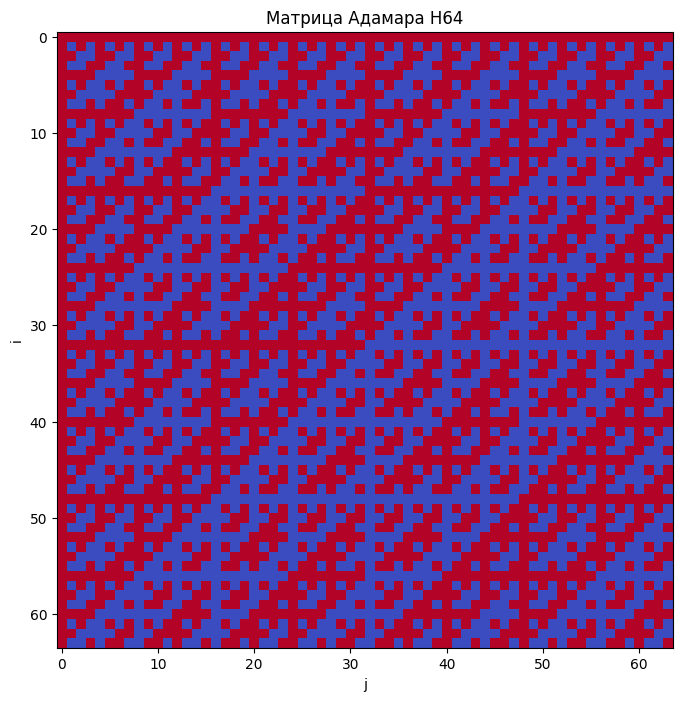

In [12]:
#1.12
import numpy as np
import matplotlib.pyplot as plt

def hadamard_matrix(k):
    if k == 0:
        return np.array([[1]])

    H = hadamard_matrix(k - 1)

    return np.block([
        [H, H],
        [H, -H]
    ])

H1 = hadamard_matrix(0)
H2 = hadamard_matrix(1)
H4 = hadamard_matrix(2)

print("H1:")
print(H1)

print()
print("H2:")
print(H2)

print()
print("H4:")
print(H4)

print()
print("Проверка H4 = H2 ⊗ H2:")
print(np.array_equal(H4, np.kron(H2, H2)))

H64 = hadamard_matrix(6)

print()
print("Проверка H64 = H2 ⊗ H32:")
print(np.array_equal(H64, np.kron(H2, hadamard_matrix(5))))

plt.figure(figsize=(8, 8))

plt.imshow(
    H64,
    cmap="coolwarm",
    interpolation="nearest"
)

plt.title("Матрица Адамара H64")
plt.xlabel("j")
plt.ylabel("i")
plt.show()

In [13]:
#1.13
import numpy as np

A = np.array([
    [14, 10, 21],
    [12, 15, 26],
    [18, 11, 27]
], dtype=float)

eigenvalues, eigenvectors = np.linalg.eig(A)

index = np.argmax(eigenvalues.imag)

Z = eigenvalues[index]

X = eigenvectors[:, index]

X = X / X[0]

print("Z =", Z)
print()
print("X =", X)
print()
print("Мнимая часть Z =", Z.imag)
print("Действительная часть U =", X[1].real)

Z = (1.9688403308016502+0.3447893484271669j)

X = [ 1.        -0.j          3.74781973+1.33084677j -2.35758843-0.61731802j]

Мнимая часть Z = 0.3447893484271669
Действительная часть U = 3.747819729394814


In [14]:
#1.14
import sympy as sp

x = sp.symbols('x')

A = sp.Matrix([
    [-3, 7, -6, -1, 8, -3, -2],
    [1, -5, 8, -3, -5, 4, -5],
    [1, 3, -4, 6, -2, 0, 8],
    [-1, 11, -12, 9, 3, -3, 9],
    [-3, 11, -12, 5, 8, -4, 6],
    [-3, 2, 1, -4, 4, 1, -7],
    [1, -5, 6, -2, -4, 3, -2]
])

char_poly = sp.factor(A.charpoly(x).as_expr())

print("Характеристический многочлен:")
print(char_poly)

I = sp.eye(7)

minimal_p = None
minimal_q = None

for p in range(1, 4):
    for q in range(1, 5):
        P = (A ** p) * ((A - I) ** q)

        if P == sp.zeros(7):
            minimal_p = p
            minimal_q = q
            break

    if minimal_p is not None:
        break

print()
print("Минимальный многочлен:")
print(f"x^{minimal_p} * (x - 1)^{minimal_q}")

Характеристический многочлен:
x**3*(x - 1)**4

Минимальный многочлен:
x^3 * (x - 1)^2


In [15]:
#1.15
import sympy as sp

A = sp.Matrix([
    [17, -8, 4],
    [-8, 17, -4],
    [4, -4, 11]
])

eigenvalues = A.eigenvects()

print("Собственные значения и собственные векторы:")
for value, multiplicity, vectors in eigenvalues:
    print("λ =", value)
    print("Векторы:")
    for vector in vectors:
        print(vector)
    print()

e1 = sp.Matrix([1, 1, 0]) / sp.sqrt(2)

v2 = sp.Matrix([-sp.Rational(1, 2), 0, 1])
v2_orthogonal = v2 - (v2.dot(e1)) * e1
e2 = v2_orthogonal / sp.sqrt(v2_orthogonal.dot(v2_orthogonal))

e3 = sp.Matrix([2, -2, 1]) / 3

P = sp.Matrix.hstack(e1, e2, e3)

print("Собственный ортонормированный базис:")
sp.pprint(P)

print()
print("Матрица оператора в новом базисе:")
sp.pprint(P.T * A * P)

Собственные значения и собственные векторы:
λ = 9
Векторы:
Matrix([[1], [1], [0]])
Matrix([[-1/2], [0], [1]])

λ = 27
Векторы:
Matrix([[2], [-2], [1]])

Собственный ортонормированный базис:
⎡√2  -√2       ⎤
⎢──  ────  2/3 ⎥
⎢2    6        ⎥
⎢              ⎥
⎢√2   √2       ⎥
⎢──   ──   -2/3⎥
⎢2    6        ⎥
⎢              ⎥
⎢    2⋅√2      ⎥
⎢0   ────  1/3 ⎥
⎣     3        ⎦

Матрица оператора в новом базисе:
⎡9  0  0 ⎤
⎢        ⎥
⎢0  9  0 ⎥
⎢        ⎥
⎣0  0  27⎦


In [16]:
#1.16
import sympy as sp

A = sp.Matrix([
    [3, 4, 0, 0],
    [4, -3, 0, 0],
    [0, 0, 4, -2],
    [0, 0, -2, 1]
])

e1 = sp.Matrix([2, 1, 0, 0]) / sp.sqrt(5)
e2 = sp.Matrix([0, 0, 2, -1]) / sp.sqrt(5)
e3 = sp.Matrix([1, -2, 0, 0]) / sp.sqrt(5)
e4 = sp.Matrix([0, 0, 1, 2]) / sp.sqrt(5)

P = sp.Matrix.hstack(e1, e2, e3, e4)

D = sp.simplify(P.T * A * P)

print("Ортогональная матрица P:")
sp.pprint(P)

print()
print("Проверка P^T * P:")
sp.pprint(sp.simplify(P.T * P))

print()
print("Диагональная матрица D:")
sp.pprint(D)

print()
print("Канонический вид:")
print("f = 5*y1^2 + 5*y2^2 - 5*y3^2")

Ортогональная матрица P:
⎡2⋅√5          √5        ⎤
⎢────   0      ──     0  ⎥
⎢ 5            5         ⎥
⎢                        ⎥
⎢ √5         -2⋅√5       ⎥
⎢ ──    0    ──────   0  ⎥
⎢ 5            5         ⎥
⎢                        ⎥
⎢      2⋅√5           √5 ⎥
⎢ 0    ────    0      ── ⎥
⎢       5             5  ⎥
⎢                        ⎥
⎢      -√5           2⋅√5⎥
⎢ 0    ────    0     ────⎥
⎣       5             5  ⎦

Проверка P^T * P:
⎡1  0  0  0⎤
⎢          ⎥
⎢0  1  0  0⎥
⎢          ⎥
⎢0  0  1  0⎥
⎢          ⎥
⎣0  0  0  1⎦

Диагональная матрица D:
⎡5  0  0   0⎤
⎢           ⎥
⎢0  5  0   0⎥
⎢           ⎥
⎢0  0  -5  0⎥
⎢           ⎥
⎣0  0  0   0⎦

Канонический вид:
f = 5*y1^2 + 5*y2^2 - 5*y3^2


In [17]:
#1.17
import sympy as sp

x, y, u, v = sp.symbols('x y u v')

# -------------------------
# a)
# -------------------------

A_a = sp.Matrix([
    [5, 2],
    [2, 8]
])

center_a = sp.Matrix([2, 3])

P_a = sp.Matrix.hstack(
    sp.Matrix([-2, 1]) / sp.sqrt(5),
    sp.Matrix([1, 2]) / sp.sqrt(5)
)

expr_a = 5*x**2 + 4*x*y + 8*y**2 - 32*x - 56*y + 80

x_a = center_a[0] + P_a[0, 0]*u + P_a[0, 1]*v
y_a = center_a[1] + P_a[1, 0]*u + P_a[1, 1]*v

canonical_a = sp.expand(
    expr_a.subs({
        x: x_a,
        y: y_a
    })
)

print("1.17 а)")
print("Центр:", center_a.T)
print("Преобразование:")
sp.pprint(P_a)
print("Новое уравнение:")
sp.pprint(canonical_a)
print("Тип: эллипс")
print("Канонический вид: u^2/9 + v^2/4 = 1")

# -------------------------
# б)
# -------------------------

A_b = sp.Matrix([
    [5, 6],
    [6, 0]
])

center_b = sp.Matrix([1, 1])

P_b = sp.Matrix.hstack(
    sp.Matrix([-2, 3]) / sp.sqrt(13),
    sp.Matrix([3, 2]) / sp.sqrt(13)
)

expr_b = 5*x**2 + 12*x*y - 22*x - 12*y - 19

x_b = center_b[0] + P_b[0, 0]*u + P_b[0, 1]*v
y_b = center_b[1] + P_b[1, 0]*u + P_b[1, 1]*v

canonical_b = sp.expand(
    expr_b.subs({
        x: x_b,
        y: y_b
    })
)

print()
print("1.17 б)")
print("Центр:", center_b.T)
print("Преобразование:")
sp.pprint(P_b)
print("Новое уравнение:")
sp.pprint(canonical_b)
print("Тип: гипербола")
print("Канонический вид: v^2/4 - u^2/9 = 1")

1.17 а)
Центр: Matrix([[2, 3]])
Преобразование:
⎡-2⋅√5    √5 ⎤
⎢──────   ── ⎥
⎢  5      5  ⎥
⎢            ⎥
⎢  √5    2⋅√5⎥
⎢  ──    ────⎥
⎣  5      5  ⎦
Новое уравнение:
   2      2     
4⋅u  + 9⋅v  - 36
Тип: эллипс
Канонический вид: u^2/9 + v^2/4 = 1

1.17 б)
Центр: Matrix([[1, 1]])
Преобразование:
⎡-2⋅√13   3⋅√13⎤
⎢───────  ─────⎥
⎢  13      13  ⎥
⎢              ⎥
⎢ 3⋅√13   2⋅√13⎥
⎢ ─────   ─────⎥
⎣  13      13  ⎦
Новое уравнение:
     2      2     
- 4⋅u  + 9⋅v  - 36
Тип: гипербола
Канонический вид: v^2/4 - u^2/9 = 1


In [18]:
#1.18
import sympy as sp

lam = sp.symbols('lambda', real=True)

A = sp.Matrix([
    [1, lam, 5],
    [lam, 4, 3],
    [5, 3, 1]
])

delta1 = A[:1, :1].det()
delta2 = A[:2, :2].det()
delta3 = A.det()

print("Δ1 =", delta1)
print("Δ2 =", sp.factor(delta2))
print("Δ3 =", sp.factor(delta3))

roots = sp.solve(sp.Eq(delta3, 0), lam)

print()
print("Корни Δ3 = 0:")
for root in roots:
    print(root, "≈", sp.N(root))

print()
print("Для положительной определённости:")
print("Δ1 > 0")
print("Δ2 > 0  -> |λ| < 2")
print("Δ3 > 0  -> 15 - 2√30 < λ < 15 + 2√30")

print()
print("Пересечение условий отсутствует.")
print("Ответ: положительно определённых значений λ нет.")

Δ1 = 1
Δ2 = -(lambda - 2)*(lambda + 2)
Δ3 = -lambda**2 + 30*lambda - 105

Корни Δ3 = 0:
15 - 2*sqrt(30) ≈ 4.04554884989668
2*sqrt(30) + 15 ≈ 25.9544511501033

Для положительной определённости:
Δ1 > 0
Δ2 > 0  -> |λ| < 2
Δ3 > 0  -> 15 - 2√30 < λ < 15 + 2√30

Пересечение условий отсутствует.
Ответ: положительно определённых значений λ нет.


In [19]:
#1.19
import sympy as sp

lam = sp.symbols('lambda', real=True)

A = sp.Matrix([
    [lam, 1, -1],
    [1, -2, 1],
    [-1, 1, -3]
])

delta1 = A[:1, :1].det()
delta2 = A[:2, :2].det()
delta3 = A.det()

print("Δ1 =", delta1)
print("Δ2 =", sp.factor(delta2))
print("Δ3 =", sp.factor(delta3))

print()
print("Для отрицательной определённости:")
print("Δ1 < 0  -> λ < 0")
print("Δ2 > 0  -> λ < -1/2")
print("Δ3 < 0  -> λ < -3/5")

print()
print("Ответ:")
print("λ < -3/5")

Δ1 = lambda
Δ2 = -2*lambda - 1
Δ3 = 5*lambda + 3

Для отрицательной определённости:
Δ1 < 0  -> λ < 0
Δ2 > 0  -> λ < -1/2
Δ3 < 0  -> λ < -3/5

Ответ:
λ < -3/5


In [20]:
# 1.20. В PDF у Q2 напечатано 2*x1 без квадрата.
# Буквально Q2 не является квадратичной формой.
# Ниже разобрано предполагаемое исправление: 2*x1**2.
print("В условии опечатка: 2*x1 не является квадратичным членом. Далее используем 2*x1**2.")
#1.20
import sympy as sp

Q1 = sp.Matrix([
    [2, 4, -2],
    [4, 9, -5],
    [-2, -5, 3]
])

Q2 = sp.Matrix([
    [2, -2, -2],
    [-2, 3, 4],
    [-2, 4, 6]
])

print("Матрица Q1:")
sp.pprint(Q1)

print()
print("Матрица Q2:")
sp.pprint(Q2)

print()
print("Собственные значения Q1:")
sp.pprint(Q1.eigenvals())

print()
print("Собственные значения Q2:")
sp.pprint(Q2.eigenvals())

print()
print("Инерция Q1:")
print("2 положительных, 0 отрицательных, 1 нулевое")

print()
print("Инерция Q2:")
print("2 положительных, 0 отрицательных, 1 нулевое")

print()
print("Формы эквивалентны над R.")

В условии опечатка: 2*x1 не является квадратичным членом. Далее используем 2*x1**2.
Матрица Q1:
⎡2   4   -2⎤
⎢          ⎥
⎢4   9   -5⎥
⎢          ⎥
⎣-2  -5  3 ⎦

Матрица Q2:
⎡2   -2  -2⎤
⎢          ⎥
⎢-2  3   4 ⎥
⎢          ⎥
⎣-2  4   6 ⎦

Собственные значения Q1:
{0: 1, 7 - √43: 1, √43 + 7: 1}

Собственные значения Q2:
⎧      11   √73     √73   11   ⎫
⎨0: 1, ── - ───: 1, ─── + ──: 1⎬
⎩      2     2       2    2    ⎭

Инерция Q1:
2 положительных, 0 отрицательных, 1 нулевое

Инерция Q2:
2 положительных, 0 отрицательных, 1 нулевое

Формы эквивалентны над R.
